In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data_path = "../data/raw/Bearing1_1/1.csv"  # Adjust path based on your exact extraction folder
df = pd.read_csv(data_path)

print(f"Data shape for file 1: {df.shape}")
print(df.head())


print('=== INFO ===')
print(df.info())
print('\n=== MISSING VALUES ===')
print(df.isnull().sum()[df.isnull().sum() > 0])

print('\n=== DUPLICATES ===')
print(f'Duplicate rows: {df.duplicated().sum()}')

print('\n=== CATEGORICAL SUMMARY ===')
print(df.describe().T)


Data shape for file 1: (32768, 2)
   Horizontal_vibration_signals  Vertical_vibration_signals
0                     -0.396395                   -0.038672
1                     -0.123107                   -0.365901
2                      0.988841                   -0.583780
3                      0.006676                   -0.013411
4                     -1.074386                    0.087607
=== INFO ===
<class 'pandas.DataFrame'>
RangeIndex: 32768 entries, 0 to 32767
Data columns (total 2 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Horizontal_vibration_signals  32768 non-null  float64
 1   Vertical_vibration_signals    32768 non-null  float64
dtypes: float64(2)
memory usage: 512.1 KB
None

=== MISSING VALUES ===
Series([], dtype: int64)

=== DUPLICATES ===
Duplicate rows: 0

=== CATEGORICAL SUMMARY ===
                                count      mean       std       min       25%  \
Horizontal_vibra

In [3]:
import sys
from pathlib import Path

# Get the path to the project root (one level up from the 'notebooks' folder)
project_root = Path.cwd().parent

# Add the project root to sys.path if it isn't already there
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Now you can import your module cleanly
from src.features import extract_signal_features

In [4]:
# Set style for cleaner plots
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)

RAW_DATA_DIR = "../data/raw"
PROCESSED_DATA_DIR = "../data/processed"

In [5]:
# List all bearing folders (e.g., Bearing1_1, Bearing1_2, etc.)
bearing_folders = sorted([f for f in os.listdir(RAW_DATA_DIR) if os.path.isdir(os.path.join(RAW_DATA_DIR, f))])
print(f"Detected Bearing Folders: {bearing_folders}")

Detected Bearing Folders: ['Bearing1_1', 'Bearing1_2', 'Bearing1_3', 'Bearing1_4', 'Bearing1_5', 'Bearing2_1', 'Bearing2_2', 'Bearing2_3', 'Bearing2_4', 'Bearing2_5', 'Bearing3_1', 'Bearing3_2', 'Bearing3_3', 'Bearing3_4', 'Bearing3_5']


Columns: Index(['Horizontal_vibration_signals', 'Vertical_vibration_signals'],
      dtype='str')


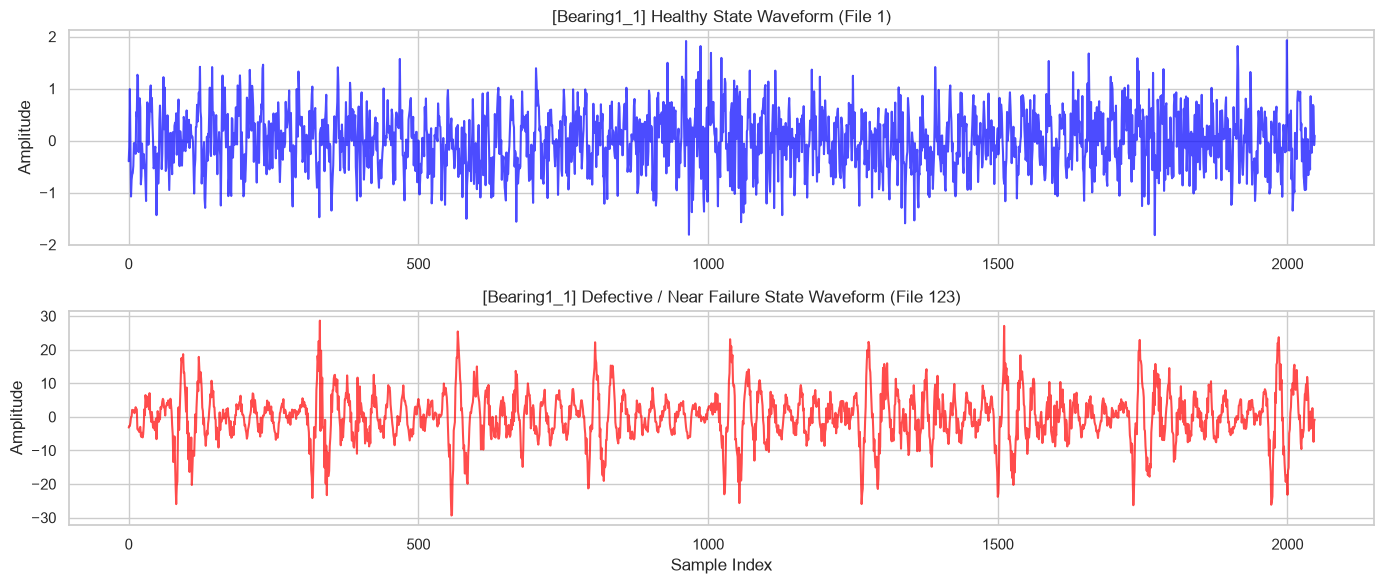

In [6]:
sample_bearing = "Bearing1_1"
bearing_path = os.path.join(RAW_DATA_DIR, sample_bearing)
csv_files = sorted(os.listdir(bearing_path), key=lambda x: int(x.split('.')[0]))

# Load first file (Healthy) and last file (Near Failure)
file_first = os.path.join(bearing_path, csv_files[0])
file_last = os.path.join(bearing_path, csv_files[-1])

df_healthy = pd.read_csv(file_first)
df_failure = pd.read_csv(file_last)

# XJTU-SY CSV files usually contain columns for horizontal and vertical acceleration
# Let's inspect column names dynamically
print("Columns:", df_healthy.columns)

fig, axes = plt.subplots(2, 1, figsize=(14, 6))
# Assuming horizontal vibration is column 0 or 1 (usually column index 0 or named appropriately)
h_col = df_healthy.columns[0] 

axes[0].plot(df_healthy[h_col].values[:2048], color='blue', alpha=0.7)
axes[0].set_title(f"[{sample_bearing}] Healthy State Waveform (File 1)")
axes[0].set_ylabel("Amplitude")

axes[1].plot(df_failure[h_col].values[:2048], color='red', alpha=0.7)
axes[1].set_title(f"[{sample_bearing}] Defective / Near Failure State Waveform (File {len(csv_files)})")
axes[1].set_xlabel("Sample Index")
axes[1].set_ylabel("Amplitude")

plt.tight_layout()
plt.show()

In [7]:
all_features = []

for bearing in bearing_folders:
    b_path = os.path.join(RAW_DATA_DIR, bearing)
    files = sorted(os.listdir(b_path), key=lambda x: int(x.split('.')[0]))
    total_lifetime_files = len(files)
    
    print(f"Processing {bearing} ({total_lifetime_files} files)...")
    
    for idx, file_name in enumerate(files):
        file_path = os.path.join(b_path, file_name)
        df_signal = pd.read_csv(file_path)
        
        # Assume col 0 = Horizontal vibration, col 1 = Vertical vibration
        h_signal = df_signal.iloc[:, 0].values
        v_signal = df_signal.iloc[:, 1].values if df_signal.shape[1] > 1 else h_signal
        
        # Extract features for both axes
        h_feats = extract_signal_features(h_signal)
        v_feats = extract_signal_features(v_signal)
        
        row = {
            "Bearing": bearing,
            "FileIndex": int(file_name.split('.')[0]),
            "TotalLifetime": total_lifetime_files,
            "RUL_Percentage": 1.0 - (int(file_name.split('.')[0]) / total_lifetime_files)
        }
        
        # Prefix feature names with H_ and V_
        for k, val in h_feats.items():
            row[f"H_{k}"] = val
        for k, val in v_feats.items():
            row[f"V_{k}"] = val
            
        all_features.append(row)

df_processed = pd.DataFrame(all_features)
output_file = os.path.join(PROCESSED_DATA_DIR, "xjtu_sy_features.parquet")
df_processed.to_parquet(output_file, index=False)
print(f"\nSuccessfully processed and saved features to {output_file}!")
print(df_processed.head())

Processing Bearing1_1 (123 files)...
Processing Bearing1_2 (161 files)...
Processing Bearing1_3 (158 files)...
Processing Bearing1_4 (122 files)...
Processing Bearing1_5 (52 files)...
Processing Bearing2_1 (491 files)...
Processing Bearing2_2 (161 files)...
Processing Bearing2_3 (533 files)...
Processing Bearing2_4 (42 files)...
Processing Bearing2_5 (339 files)...
Processing Bearing3_1 (2538 files)...
Processing Bearing3_2 (2496 files)...
Processing Bearing3_3 (371 files)...
Processing Bearing3_4 (1515 files)...
Processing Bearing3_5 (114 files)...

Successfully processed and saved features to ../data/processed\xjtu_sy_features.parquet!
      Bearing  FileIndex  TotalLifetime  RUL_Percentage     H_RMS    H_Peak  \
0  Bearing1_1          1            123         0.99187  0.563890  2.529883   
1  Bearing1_1          2            123         0.98374  0.589078  3.623104   
2  Bearing1_1          3            123         0.97561  0.589536  3.321779   
3  Bearing1_1          4            12

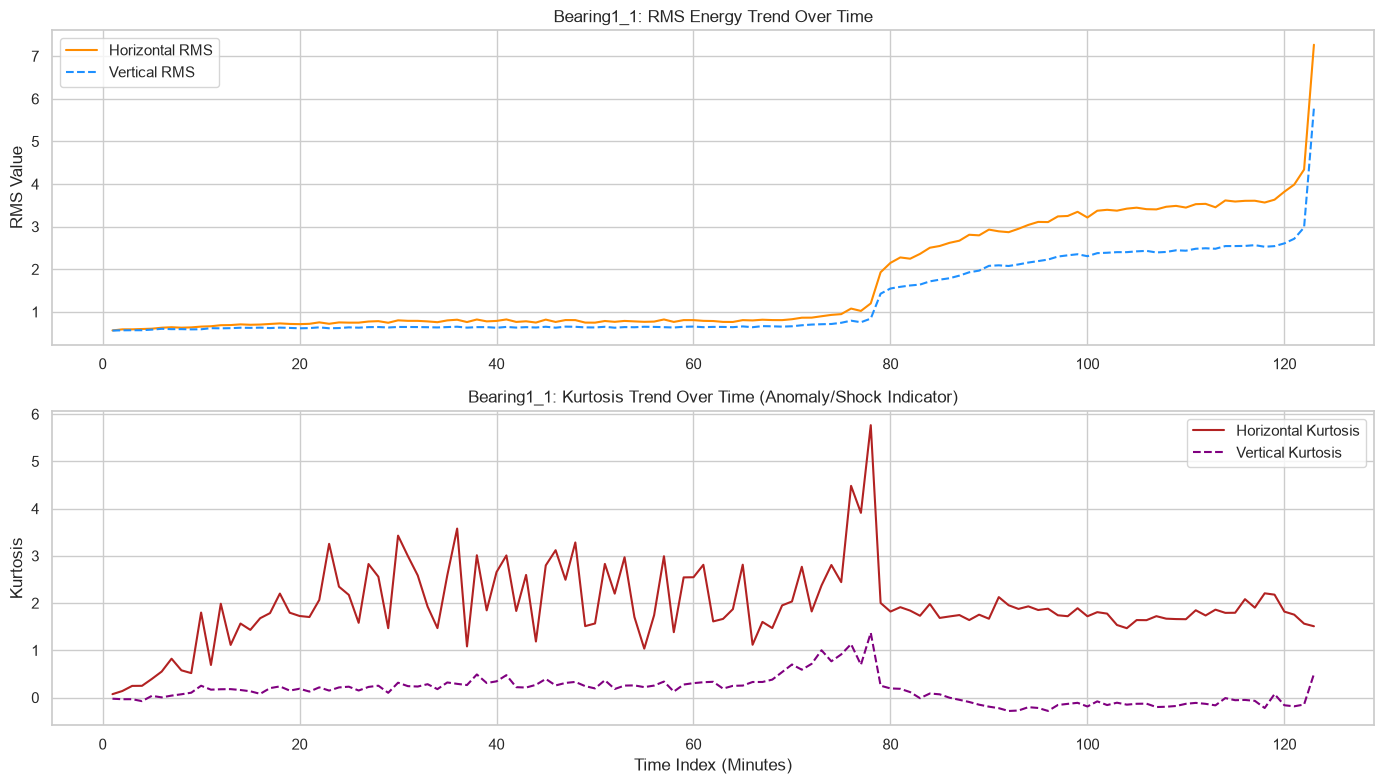

In [8]:
# Filter for Bearing1_1
b1_data = df_processed[df_processed["Bearing"] == "Bearing1_1"]

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# RMS Trend (Energy growth indicating wear)
axes[0].plot(b1_data["FileIndex"], b1_data["H_RMS"], label="Horizontal RMS", color="darkorange")
axes[0].plot(b1_data["FileIndex"], b1_data["V_RMS"], label="Vertical RMS", color="dodgerblue", linestyle="--")
axes[0].set_title("Bearing1_1: RMS Energy Trend Over Time")
axes[0].set_ylabel("RMS Value")
axes[0].legend()

# Kurtosis Trend (Impulsiveness spike when defects strike raceways/balls)
axes[1].plot(b1_data["FileIndex"], b1_data["H_Kurtosis"], label="Horizontal Kurtosis", color="firebrick")
axes[1].plot(b1_data["FileIndex"], b1_data["V_Kurtosis"], label="Vertical Kurtosis", color="purple", linestyle="--")
axes[1].set_title("Bearing1_1: Kurtosis Trend Over Time (Anomaly/Shock Indicator)")
axes[1].set_xlabel("Time Index (Minutes)")
axes[1].set_ylabel("Kurtosis")
axes[1].legend()

plt.tight_layout()
plt.show()